# Reviewly: transformer sentiment comparison

This standalone notebook fine-tunes BERT, ELECTRA, and DistilBERT on product reviews, compares held-out accuracy, macro precision, macro recall, macro F1, training time, and test inference time, then uses the top model to summarize product feedback.

The third model is DistilBERT because ELECTRA was named twice in the request; this gives three distinct architectures. These are pretrained encoders with newly initialized sentiment heads, which this notebook fine-tunes.

Important: star ratings are weak labels, not verified sentiment truth. Use a human-checked human_sentiment column for a stronger accuracy claim.

## 1. Install dependencies

Run once in the Jupyter environment. The pretrained weights download from Hugging Face; a GPU is recommended.

In [3]:
%pip install -q transformers datasets accelerate scikit-learn pandas matplotlib seaborn

In [4]:
from datasets import Dataset
import random

import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
)
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    pipeline,
)

## 2. Load the Reviewly export and prepare labels

The project already contains an app export at data/product-reviews.csv. Set DATA_PATH to another export if you want to compare a different review sample. Reviewly exports Review and Rating columns. A human_sentiment column (positive/negative) takes priority. Otherwise, 1-2 star ratings map to negative and 4-5 map to positive; 3-star and unrated rows are excluded. The app's generated VADER Sentiment column is not used as ground truth.

 Find the project and load the CSV

In [5]:
from pathlib import Path
import pandas as pd

matches = list(Path("/content").rglob("product-reviews.csv"))
if not matches:
    raise FileNotFoundError("Upload product-reviews.csv to Colab first.")

DATA_PATH = matches[0]
OUTPUT_DIR = Path("/content/outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
print("Loaded", len(df), "reviews from", DATA_PATH)

Loaded 50 reviews from /content/product-reviews.csv


# Clean the review text

In [6]:
TEXT_COLUMNS = ["Review", "review", "text", "Text", "content"]

df.columns = [str(column).strip() for column in df.columns]

text_column = next(
    (column for column in TEXT_COLUMNS if column in df.columns),
    None
)

if text_column is None:
    raise ValueError(f"No review text column found. Columns: {list(df.columns)}")

df = df.rename(columns={text_column: "text"})
df["text"] = df["text"].fillna("").astype(str).str.strip()
df = df[df["text"].str.len() > 0].drop_duplicates(subset="text").copy()

# Keep all reviews for the quick transformer demo.
raw_reviews = df.copy()

print("Reviews with text:", len(df))

Reviews with text: 50


# Define how sentiment labels are read

In [7]:
import numpy as np

def normalize_label(value):
    value = str(value).strip().lower()

    if value in {"positive", "pos", "good", "1"}:
        return "positive"

    if value in {"negative", "neg", "bad", "0"}:
        return "negative"

    return np.nan

# Create sentiment labels

In [8]:
RATING_COLUMNS = ["Rating", "rating", "stars", "Stars"]

if "human_sentiment" in df.columns:
    df["sentiment"] = df["human_sentiment"].map(normalize_label)
    label_source = "human-provided sentiment labels"
else:
    rating_column = next(
        (column for column in RATING_COLUMNS if column in df.columns),
        None
    )

    if rating_column is None:
        raise ValueError("The CSV needs a rating column or human_sentiment labels.")

    ratings = pd.to_numeric(df[rating_column], errors="coerce")
    df["sentiment"] = np.nan
    df.loc[ratings <= 2, "sentiment"] = "negative"
    df.loc[ratings >= 4, "sentiment"] = "positive"

    label_source = f"labels inferred from the {rating_column} ratings"

df = df.dropna(subset=["sentiment"])[["text", "sentiment"]].reset_index(drop=True)
df["label"] = df["sentiment"].map({"negative": 0, "positive": 1}).astype(int)

/tmp/ipykernel_35713/3263572338.py:17: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'negative' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.loc[ratings <= 2, "sentiment"] = "negative"


# Check whether there is enough data to compare models


In [9]:
print("Usable labeled reviews:", len(df))
print("Label source:", label_source)
print(df["sentiment"].value_counts())

CAN_TRAIN_COMPARISON = (
    df["label"].nunique() == 2
    and df["label"].value_counts().min() >= 10
)

if CAN_TRAIN_COMPARISON:
    print("There are enough examples in both classes to continue.")
else:
    print("There are too few examples in one class for a reliable model comparison.")
    print("The quick transformer prediction demo can still run.")

Usable labeled reviews: 45
Label source: labels inferred from the Rating ratings
sentiment
positive    40
negative     5
Name: count, dtype: int64
There are too few examples in one class for a reliable model comparison.
The quick transformer prediction demo can still run.


## Quick transformer check (no fine-tuning)

Run this cell after loading the CSV to get a quick output from a pretrained DistilBERT sentiment model. It scores 10 reviews by default, so you can confirm the pipeline before training. Set `QUICK_SAMPLE_SIZE = None` to score every review. This checkpoint was fine-tuned on movie sentiment, so treat its product-review predictions as a smoke test, not a final product-specific result.

Choose a sample

In [10]:
QUICK_MODEL = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
QUICK_SAMPLE_SIZE = 10  # Use None to score all reviews

if QUICK_SAMPLE_SIZE is None:
    quick_input = raw_reviews.copy()
else:
    quick_input = raw_reviews.head(QUICK_SAMPLE_SIZE).copy()

print("Reviews to check:", len(quick_input))

Reviews to check: 10


Load the transformer

In [11]:
import torch
from transformers import pipeline
quick_classifier = pipeline(
    "text-classification",
    model=QUICK_MODEL,
    device=0 if torch.cuda.is_available() else -1,
)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Predict and save the results

In [12]:
quick_predictions = quick_classifier(
    quick_input["text"].tolist(),
    batch_size=8,
    truncation=True,
    max_length=256,
)

quick_input["Transformer prediction"] = [
    prediction["label"].lower()
    for prediction in quick_predictions
]

quick_input["Transformer confidence"] = [
    round(float(prediction["score"]), 4)
    for prediction in quick_predictions
]

quick_output_path = OUTPUT_DIR / "quick_transformer_predictions.csv"
quick_input.to_csv(quick_output_path, index=False, encoding="utf-8-sig")

display(
    quick_input[
        ["text", "Transformer prediction", "Transformer confidence"]
    ]
)

print(f"Saved {len(quick_input)} predictions to {quick_output_path}")

,text,Transformer prediction,Transformer confidence
0,Worth the money: Good,positive,0.9999
1,Good choice: Nice and smooth quality earbuds o...,positive,0.9998
2,Mind-blowing purchase: I hope you guys find th...,positive,0.9986
3,Does the job: Review after 5 months: Not good ...,negative,0.9464
4,Good choice: Boat has decent quality. The prod...,positive,0.9997
5,Good quality product: Awesome 👍🏻😍,positive,0.9999
6,Pretty good: Awesome 👍👍👍👍,positive,0.9999
7,Brilliant: (1) Worth of the money 💰 (2) Nice d...,positive,0.9998
8,Wonderful: Worth money fr buying this product ...,positive,0.9937
9,Wonderful: Best product you can buy in this pr...,positive,0.9998


Saved 10 predictions to /content/outputs/quick_transformer_predictions.csv


if not CAN_TRAIN_COMPARISON:
    raise ValueError("Not enough examples in the smaller sentiment class for a stable three-way split. Collect at least 10 per class to run; 50 or more per class across multiple products is better.")
## 3. Make one stratified split for every model

The test split stays held out for final scoring. All three models use the same rows.

In [13]:
from sklearn.model_selection import train_test_split
SEED =42
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"],
)

valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"],
)

for name, part in [
    ("Train", train_df),
    ("Validation", valid_df),
    ("Test", test_df),
]:
    print(name, len(part), part["sentiment"].value_counts().to_dict())

Train 31 {'positive': 28, 'negative': 3}
Validation 7 {'positive': 6, 'negative': 1}
Test 7 {'positive': 6, 'negative': 1}


## 4. Fine-tune the three transformer encoders

Settings are kept fixed for a fair comparison. Training all three may take a while on CPU.

Model settings

In [17]:
checkpoint = "google-bert/bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
MODELS = {
    "BERT": "google-bert/bert-base-uncased",
    "ELECTRA": "google/electra-base-discriminator",
    "DistilBERT": "distilbert/distilbert-base-uncased",
}

ID2LABEL = {0: "NEGATIVE", 1: "POSITIVE"}
LABEL2ID = {"negative": 0, "positive": 1}

MAX_LENGTH = 256
EPOCHS = 20
TRAIN_BATCH = 8
EVAL_BATCH = 16
LEARNING_RATE = 2e-5

MODEL_OUTPUT_DIR = OUTPUT_DIR / "transformer_models"
MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

Dataset and metric helpers

In [18]:
def make_dataset(frame, tokenizer):
    source = Dataset.from_pandas(
        frame[["text", "label"]].reset_index(drop=True),
        preserve_index=False,
    )

    return source.map(
        lambda batch: tokenizer(
            batch["text"],
            truncation=True,
            max_length=MAX_LENGTH,
        ),
        batched=True,
    )


def metric_fn(eval_pred):
    logits, labels = eval_pred
    predicted = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predicted,
        average="macro",
        zero_division=0,
    )

    return {
        "accuracy": accuracy_score(labels, predicted),
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1,
    }

Train and evaluate each model

In [23]:
from transformers import AutoTokenizer
import time
tokenizer = AutoTokenizer.from_pretrained(checkpoint)


In [25]:
import warnings
warnings.filterwarnings(
    "ignore",
    message="'pin_memory' argument is set as true but no accelerator is found",
)
import gc
runs = []
predictions_by_model = {}

for model_name, checkpoint in MODELS.items():
    print("Training", model_name)

    tokenizer = AutoTokenizer.from_pretrained(checkpoint)

    train_ds = make_dataset(train_df, tokenizer)
    valid_ds = make_dataset(valid_df, tokenizer)
    test_ds = make_dataset(test_df, tokenizer)

    model = AutoModelForSequenceClassification.from_pretrained(
        checkpoint,
        num_labels=2,
        id2label=ID2LABEL,
        label2id=LABEL2ID,
    )

    model_dir = str(MODEL_OUTPUT_DIR / model_name.lower())

    args = TrainingArguments(
        output_dir=model_dir,
        learning_rate=LEARNING_RATE,
        per_device_train_batch_size=TRAIN_BATCH,
        per_device_eval_batch_size=EVAL_BATCH,
        num_train_epochs=EPOCHS,
        weight_decay=0.01,
        warmup_steps=0.1,
        eval_strategy="epoch",
        save_strategy="no",
        logging_strategy="epoch",
        report_to="none",
        seed=SEED,
        data_seed=SEED,
        fp16=torch.cuda.is_available(),
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=valid_ds,
        processing_class=tokenizer,
        data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=metric_fn,
    )

    started = time.perf_counter()
    trainer.train()
    training_seconds = time.perf_counter() - started

    valid_metrics = trainer.evaluate(valid_ds)
    test_output = trainer.predict(test_ds)

    y_true = test_df["label"].to_numpy()
    y_pred = np.argmax(test_output.predictions, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0,
    )

    trainer.save_model(model_dir)
    tokenizer.save_pretrained(model_dir)

    runs.append({
        "model": model_name,
        "checkpoint": checkpoint,
        "validation_f1_macro": valid_metrics.get("eval_f1_macro", np.nan),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1,
        "training_seconds": training_seconds,
        "test_inference_seconds": test_output.metrics.get("test_runtime", np.nan),
        "model_dir": model_dir,
    })

    predictions_by_model[model_name] = y_pred

    print(classification_report(
        y_true,
        y_pred,
        target_names=["negative", "positive"],
        zero_division=0,
    ))

    del trainer, model, tokenizer, train_ds, valid_ds, test_ds
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    if model_name in predictions_by_model:
        print("Already completed, skipping", model_name)
        continue

Training BERT


Map:   0%|          | 0/31 [00:00<?, ? examples/s]

Map:   0%|          | 0/7 [00:00<?, ? examples/s]

Map:   0%|          | 0/7 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (33 outputs left out)

Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
1,0.625811,0.621444,0.857143,0.428571,0.500000,0.461538
2,0.562044,0.540722,0.857143,0.428571,0.500000,0.461538
3,0.462522,0.446940,0.857143,0.428571,0.500000,0.461538
4,0.340809,0.389532,0.857143,0.428571,0.500000,0.461538
5,0.268959,0.373050,0.857143,0.428571,0.500000,0.461538
6,0.215916,0.381879,0.857143,0.428571,0.500000,0.461538
7,0.175166,0.391560,0.857143,0.428571,0.500000,0.461538
8,0.135575,0.401917,0.857143,0.428571,0.500000,0.461538
9,0.103257,0.423300,0.857143,0.428571,0.500000,0.461538
10,0.103086,0.447920,0.857143,0.428571,0.500000,0.461538


Training Loss,Validation Loss,Epoch,Accuracy,Precision Macro,Recall Macro,F1 Macro
0.037371,0.512035,20,0.857143,0.428571,0.500000,0.461538


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         1
    positive       0.86      1.00      0.92         6

    accuracy                           0.86         7
   macro avg       0.43      0.50      0.46         7
weighted avg       0.73      0.86      0.79         7

Already completed, skipping DistilBERT


## 5. Compare scores and inspect mistakes

Macro-F1 weighs positive and negative classes equally. Accuracy alone can be misleading when the classes are imbalanced.

Plot the model scores

In [27]:
print([run["model"] for run in runs])

['BERT', 'ELECTRA', 'DistilBERT']


In [28]:
results = pd.DataFrame(runs).sort_values(
    ["validation_f1_macro", "accuracy", "test_inference_seconds"],
    ascending=[False, False, True],
).reset_index(drop=True)

display(results)

best_model_name = results.loc[0, "model"]
best_model_dir = results.loc[0, "model_dir"]
print("Best by validation macro-F1:", best_model_name)

,model,checkpoint,validation_f1_macro,accuracy,precision_macro,recall_macro,f1_macro,training_seconds,test_inference_seconds,model_dir
0,DistilBERT,distilbert/distilbert-base-uncased,0.461538,0.857143,0.428571,0.5,0.461538,349.415773,2.2902,/content/outputs/transformer_models/distilbert
1,BERT,google-bert/bert-base-uncased,0.461538,0.857143,0.428571,0.5,0.461538,693.527941,4.2477,/content/outputs/transformer_models/bert
2,ELECTRA,google/electra-base-discriminator,0.461538,0.857143,0.428571,0.5,0.461538,801.911812,4.6855,/content/outputs/transformer_models/electra


Best by validation macro-F1: DistilBERT


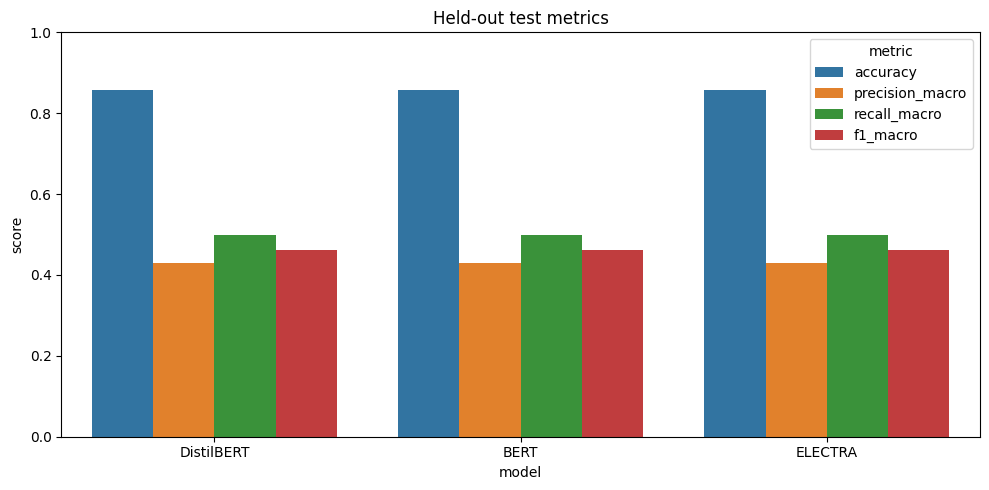

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_data = results.melt(
    id_vars="model",
    value_vars=["accuracy", "precision_macro", "recall_macro", "f1_macro"],
    var_name="metric",
    value_name="score",
)

plt.figure(figsize=(10, 5))
sns.barplot(data=plot_data, x="model", y="score", hue="metric")
plt.ylim(0, 1)
plt.title("Held-out test metrics")
plt.tight_layout()
plt.show()

## 6. Summarize product feedback with the selected model

This majority-threshold summary is an estimate for the available sample, not a guarantee of product quality.

Analyze all reviews with the selected model

In [30]:
device_id = 0 if torch.cuda.is_available() else -1

classifier = pipeline(
    "text-classification",
    model=best_model_dir,
    tokenizer=best_model_dir,
    device=device_id,
)

predictions = classifier(
    df["text"].tolist(),
    batch_size=16,
    truncation=True,
    max_length=MAX_LENGTH,
)

labels = [item["label"].lower() for item in predictions]

positive_share = labels.count("positive") / len(labels)
negative_share = labels.count("negative") / len(labels)

if positive_share >= 0.60:
    overall_signal = "Likely positive customer feedback"
elif negative_share >= 0.60:
    overall_signal = "Likely negative customer feedback"
else:
    overall_signal = "Mixed customer feedback"

print("Selected model:", best_model_name)
print("Reviews analyzed:", len(labels))
print(f"Positive: {positive_share:.1%} | Negative: {negative_share:.1%}")
print("Overall signal:", overall_signal)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Selected model: DistilBERT
Reviews analyzed: 45
Positive: 93.3% | Negative: 6.7%
Overall signal: Likely positive customer feedback


Save the comparison results

In [32]:
comparison_path = OUTPUT_DIR / "transformer_comparison.csv"
results.to_csv(comparison_path, index=False)

print(f"Saved comparison to {comparison_path}")
print(f"Fine-tuned models are in {MODEL_OUTPUT_DIR}")

print("File path:", comparison_path.resolve())
print("File exists:", comparison_path.exists())

from google.colab import files
files.download(str(comparison_path))

Saved comparison to /content/outputs/transformer_comparison.csv
Fine-tuned models are in /content/outputs/transformer_models
File path: /content/outputs/transformer_comparison.csv
File exists: True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
display(pd.read_csv(comparison_path))

,model,checkpoint,validation_f1_macro,accuracy,precision_macro,recall_macro,f1_macro,training_seconds,test_inference_seconds,model_dir
0,DistilBERT,distilbert/distilbert-base-uncased,0.461538,0.857143,0.428571,0.5,0.461538,349.415773,2.2902,/content/outputs/transformer_models/distilbert
1,BERT,google-bert/bert-base-uncased,0.461538,0.857143,0.428571,0.5,0.461538,693.527941,4.2477,/content/outputs/transformer_models/bert
2,ELECTRA,google/electra-base-discriminator,0.461538,0.857143,0.428571,0.5,0.461538,801.911812,4.6855,/content/outputs/transformer_models/electra


In [34]:
display(
    results[
        ["model", "accuracy", "precision_macro", "recall_macro", "f1_macro"]
    ].sort_values("f1_macro", ascending=False)
)

print("Best model by macro F1:", results.loc[results["f1_macro"].idxmax(), "model"])

,model,accuracy,precision_macro,recall_macro,f1_macro
0,DistilBERT,0.857143,0.428571,0.5,0.461538
1,BERT,0.857143,0.428571,0.5,0.461538
2,ELECTRA,0.857143,0.428571,0.5,0.461538


Best model by macro F1: DistilBERT


In [36]:
print("Actual test labels:")
print(test_df["sentiment"].value_counts())
from sklearn.metrics import confusion_matrix
for model_name, y_pred in predictions_by_model.items():
    print(f"\n{model_name} predicted labels:")
    print(pd.Series(y_pred).map({0: "negative", 1: "positive"}).value_counts())

    display(pd.DataFrame(
        confusion_matrix(test_df["label"], y_pred),
        index=["actual negative", "actual positive"],
        columns=["predicted negative", "predicted positive"],
    ))

Actual test labels:
sentiment
positive    6
negative    1
Name: count, dtype: int64

BERT predicted labels:
positive    7
Name: count, dtype: int64


,predicted negative,predicted positive
actual negative,0,1
actual positive,0,6



ELECTRA predicted labels:
positive    7
Name: count, dtype: int64


,predicted negative,predicted positive
actual negative,0,1
actual positive,0,6



DistilBERT predicted labels:
positive    7
Name: count, dtype: int64


,predicted negative,predicted positive
actual negative,0,1
actual positive,0,6


## Notes and references

The notebook does not decide in advance which model wins: it ranks results by held-out macro-F1. Rating-derived labels are weak supervision; report agreement with rating labels instead of definitive accuracy. For stronger evidence, add human-checked labels, use more products, and split by product to reduce near-duplicate leakage.

References: [Transformers sequence classification guide](https://huggingface.co/docs/transformers/en/tasks/sequence_classification), [BERT](https://huggingface.co/google-bert/bert-base-uncased), [ELECTRA](https://huggingface.co/google/electra-base-discriminator), [DistilBERT](https://huggingface.co/distilbert/distilbert-base-uncased).